# Layer 3 in practice: hot gas

This notebook executes the material of {doc}`../layer3_hot_gas`: the profiles of
the Descriptive Parametric Model at three halo masses, the scaling relations they
integrate to, their Fourier transforms in the three tracer views, the energy
closure, and the cosmic baryon budget of the matter field.
It runs on a `pip install` of `ggah_mod` plus `matplotlib`.
Layer 3 is work in progress, and the notice it emits on import is silenced below.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

import warnings

import matplotlib.pyplot as plt
import numpy as np

import ggah_mod
warnings.filterwarnings("ignore", category=ggah_mod.WorkInProgressWarning)

import ggah_mod.sectors as S
from ggah_mod import DIFFERENTIABLE
from ggah_mod.cosmology import PLANCK18, make_pk
from ggah_mod.halos.field import make_field

plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (6.4, 4.0),
                     "axes.grid": True, "grid.alpha": 0.3})
print(f"ggah_mod {ggah_mod.__version__}, jax {jax.__version__}")

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ggah_mod 1.7.0, jax 0.10.2


## The halo field and the sector

The field is at $z = 0.2$, the redshift at which layer 3 is drawn, with the
`200m` mass definition.
The sector is at its defaults: the `apec` cooling function and no density
scatter.

In [2]:
field = make_field(PLANCK18, DIFFERENTIABLE, make_pk("emu_pk"), z=0.2)
m = np.asarray(field.m)
ok = (m > 3e11) & (m < 3e15)
gas, dp = S.HotGasDPM(backend=DIFFERENTIABLE), S.DpmParams()
z, cosmo, mdef = field.z, field.cosmo, field.mdef

masses = np.array([1e12, 1e13, 1e14, 1e15])
idx = np.searchsorted(m, masses)
on = dict(conc=field.conc[idx], mdef=mdef)
x = np.logspace(-2, np.log10(2.5), 120)                     # r / R_Delta
r = np.asarray(field.r_delta)[idx, None] * x[None, :]      # (NM, n) h^-1 Mpc

## The profiles

*(a)* The electron density, *(b)* the electron pressure, *(c)* the temperature
$kT = P_{\rm e}/n_{\rm e}$ and *(d)* the metallicity, against radius in units of
$R_\Delta$, at four halo masses.

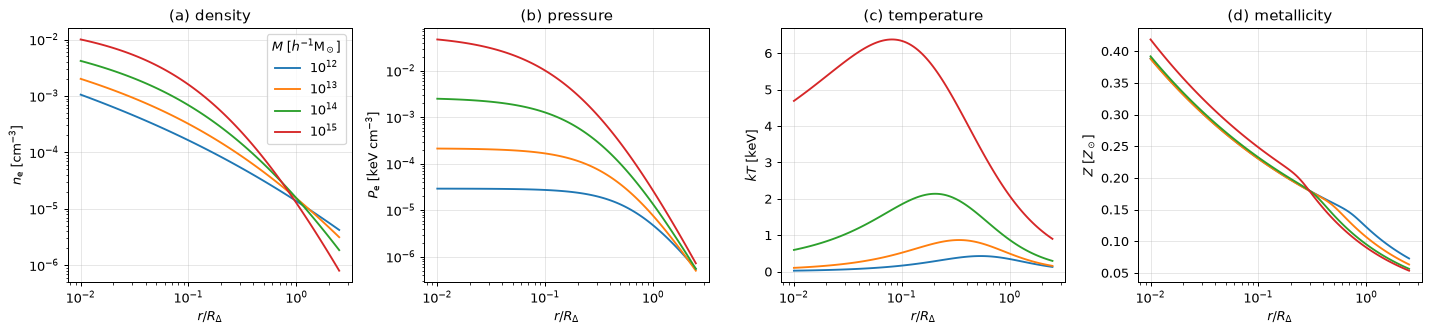

In [3]:
n_e = np.asarray(gas.n_e(r, masses, z, cosmo, dp, **on))
p_e = np.asarray(gas.pressure(r, masses, z, cosmo, dp, **on))
kt = np.asarray(gas.temperature(r, masses, z, cosmo, dp, **on))
met = np.asarray(gas.metallicity(r, masses, z, cosmo, dp, **on))

fig, ax = plt.subplots(1, 4, figsize=(16.0, 3.8))
for i, mm in enumerate(masses):
    lab = rf"$10^{{{np.log10(mm):.0f}}}$"
    ax[0].loglog(x, n_e[i], f"C{i}", label=lab)
    ax[1].loglog(x, p_e[i], f"C{i}")
    ax[2].semilogx(x, kt[i], f"C{i}")
    ax[3].semilogx(x, met[i], f"C{i}")
for a, y, t in zip(ax, (r"$n_{\rm e}$ [cm$^{-3}$]", r"$P_{\rm e}$ [keV cm$^{-3}$]",
                        "$kT$ [keV]", r"$Z\ [Z_\odot]$"),
                   ("(a) density", "(b) pressure", "(c) temperature", "(d) metallicity")):
    a.set(xlabel=r"$r/R_\Delta$", ylabel=y, title=t)
ax[0].legend(title=r"$M\ [h^{-1}{\rm M}_\odot]$")
fig.tight_layout()

## Scaling relations

On the whole mass grid, within $R_\Delta$ for the gas fraction and within the
truncation radius for the others: *(a)* the gas fraction against the cosmic
baryon fraction, *(b)* $Y$ against mass, *(c)* $L_X$ in the rest-frame
$0.5$–$2$ keV band against the emission-weighted temperature.

M = 1e+13: f_gas = 0.064, kT_X = 0.66 keV, L_X = 3.78e+41 erg/s
M = 1e+14: f_gas = 0.083, kT_X = 1.63 keV, L_X = 8.11e+42 erg/s
M = 1e+15: f_gas = 0.109, kT_X = 5.68 keV, L_X = 2.95e+44 erg/s


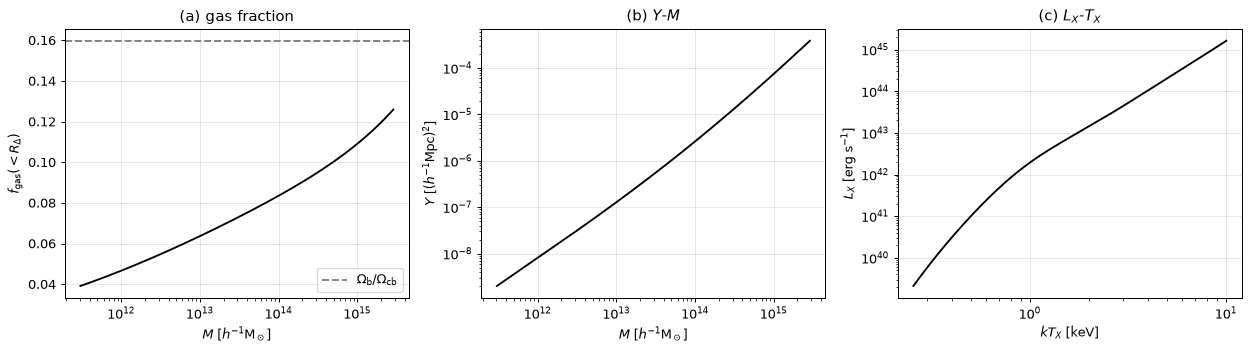

In [4]:
mm = m[ok]
kw = dict(conc=field.conc[ok], mdef=mdef)
f_gas = np.asarray(gas.f_gas(mm, z, cosmo, dp, **kw))
y = np.asarray(gas.y_amplitude(mm, z, cosmo, dp, **kw))
lx = np.asarray(gas.x_ray_luminosity(mm, z, cosmo, dp, **kw))
tx = np.asarray(gas.x_ray_temperature(mm, z, cosmo, dp, **kw))
f_b = float(S.cosmic_baryon_fraction(cosmo))

fig, ax = plt.subplots(1, 3, figsize=(14.0, 4.0))
ax[0].semilogx(mm, f_gas, "k")
ax[0].axhline(f_b, color="0.5", ls="--", label=r"$\Omega_{\rm b}/\Omega_{\rm cb}$")
ax[0].set(xlabel=r"$M\ [h^{-1}{\rm M}_\odot]$", ylabel=r"$f_{\rm gas}(<R_\Delta)$", title="(a) gas fraction")
ax[0].legend()
ax[1].loglog(mm, y, "k")
ax[1].set(xlabel=r"$M\ [h^{-1}{\rm M}_\odot]$", ylabel=r"$Y\ [(h^{-1}{\rm Mpc})^2]$", title="(b) $Y$-$M$")
ax[2].loglog(tx, lx, "k")
ax[2].set(xlabel=r"$kT_X$ [keV]", ylabel=r"$L_X$ [erg s$^{-1}$]", title=r"(c) $L_X$-$T_X$")
fig.tight_layout()
for target in (1e13, 1e14, 1e15):
    j = np.searchsorted(mm, target)
    print(f"M = {target:.0e}: f_gas = {f_gas[j]:.3f}, kT_X = {tx[j]:.2f} keV, L_X = {lx[j]:.2e} erg/s")

## Fourier profiles

The normalised transforms $u(k|M)$ the three tracer views carry, at
$10^{14}\,h^{-1}{\rm M}_\odot$: pressure (thermal SZ), emissivity (X-ray) and
density (gas mass), with the density cut at $R_\Delta$ (`bound_uk`) dashed.

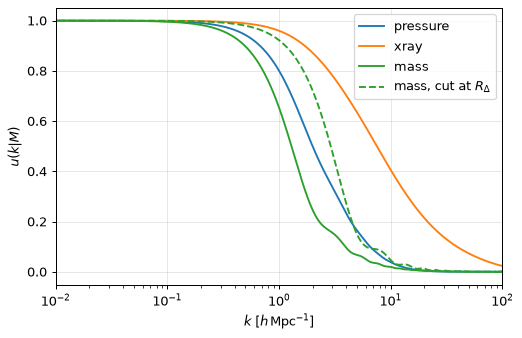

In [5]:
k = np.asarray(field.k)
j = np.searchsorted(m, 1e14)
fig, ax = plt.subplots()
for view, c in (("pressure", "C0"), ("xray", "C1"), ("mass", "C2")):
    w = gas.weights(field, dp, view=view)
    u = np.asarray(w.w_extended)[:, j]
    ax.semilogx(k, u / u[0], c, label=view)
ub = np.asarray(gas.bound_uk(field.k, field.m, z, cosmo, dp, mdef, conc=field.conc))[:, j]
ax.semilogx(k, ub, "C2--", label=r"mass, cut at $R_\Delta$")
ax.set(xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel=r"$u(k|M)$", xlim=(1e-2, 1e2))
ax.legend()

## The energy closure

The hot-gas fraction the closure retains, built with the default AGN and galaxy
sectors as peers, against the fraction the profile holds within $R_\Delta$ at its
defaults and the cosmic baryon fraction; the stars of the central galaxies and
the satellites are dotted.

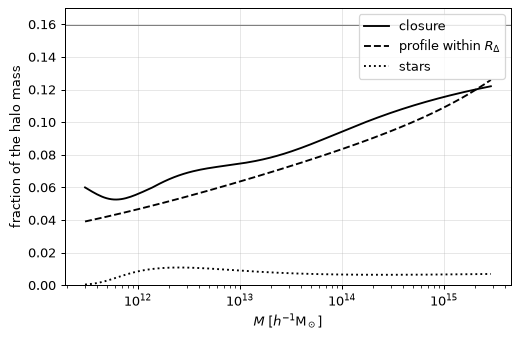

In [6]:
gal = S.GalaxySector("zumandelbaum15", calibration="off")
gp = S.galaxy_defaults("zumandelbaum15")
agn = S.AgnSector(gal, calibration="off")
closed = S.HotGasDPM(backend=DIFFERENTIABLE, feedback="closure", agn=agn, galaxies=gal)
f_budget = np.asarray(closed.feedback_budget(field, dp, S.AgnParams(), gp))
f_cen, f_sat = (np.asarray(f) for f in gal.stellar_fraction(field, gp, satellites=True))

fig, ax = plt.subplots()
ax.semilogx(m[ok], f_budget[ok], "k", label="closure")
ax.semilogx(mm, f_gas, "k--", label=r"profile within $R_\Delta$")
ax.semilogx(m[ok], (f_cen + f_sat)[ok], "k:", label="stars")
ax.axhline(f_b, color="0.5", lw=0.8)
ax.set(xlabel=r"$M\ [h^{-1}{\rm M}_\odot]$", ylabel="fraction of the halo mass", ylim=(0, 0.17))
ax.legend()

## The cosmic baryon budget

The split whose hot gas is the profile's own, with the stars of the galaxy
sector and no neutral gas, integrated over the mass function: the share of
$\Omega_{\rm b}$ each phase holds per dex of halo mass, and in total.

hot       0.168 of Omega_b
star_cen  0.010 of Omega_b
star_sat  0.008 of Omega_b
cold      0.000 of Omega_b
ejected   0.289 of Omega_b
outside   0.526 (grid holds 0.474 of the cold matter)


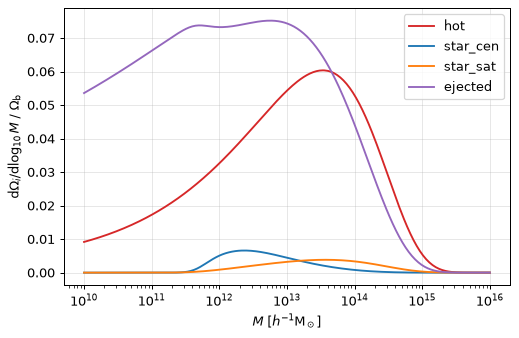

In [7]:
split = S.EjectaSector.split_from_gas(field, gas, dp, f_star_cen=f_cen, f_star_sat=f_sat)
budget = S.census(field, split)
ob = float(budget.omega_b)

fig, ax = plt.subplots()
for phase, c in zip(S.PHASES, ("C3", "C0", "C1", "C2", "C4")):
    d = np.asarray(budget.d_omega_dlog10m[phase]) / ob
    if d.max() > 0:
        ax.semilogx(m, d, c, label=phase)
ax.set(xlabel=r"$M\ [h^{-1}{\rm M}_\odot]$",
       ylabel=r"${\rm d}\Omega_i/{\rm d}\log_{10}M\ /\ \Omega_{\rm b}$")
ax.legend()
for phase, omega in budget.omega.items():
    print(f"{phase:9s} {float(omega) / ob:.3f} of Omega_b")
print(f"outside   {float(budget.omega_outside) / ob:.3f} (grid holds {float(budget.mass_fraction_in_halos):.3f} of the cold matter)")

## Things to try

- Build the sector with `cooling=S.make_cooling("apec_wide")` and
  `scatter="isobaric"`, the settings the defaults were fitted with, and compare
  the $L_X$–$T_X$ relation.
- Set `aperture` to $R_{500{\rm c}}/R_\Delta$ for a gas fraction within
  $R_{500{\rm c}}$.
- Pass `EnergeticsParams(agn_energy="soltan", eps_sn=0.1)` to the closure's
  `energetics=` for the closure of version 1.6.0.
- Move `eta_ej` in `S.EjectaParams` and follow the ejected gas in the matter
  field's spectrum ({doc}`layer4_spectra`).

Previous: {doc}`layer3_agn`. Next: {doc}`layer4_spectra`.